In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt 

from sklearn.datasets import load_wine, load_digits
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

In [3]:
wine = load_wine()

X = wine.data
y = wine.target
feat_names = wine.feature_names
target_names = wine.target_names

print("Original dataset shape:", X.shape)
print("Target shape:", y.shape)
print("Feature names:", feat_names)
print("Target names:", target_names)

Original dataset shape: (178, 13)
Target shape: (178,)
Feature names: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280/od315_of_diluted_wines', 'proline']
Target names: ['class_0' 'class_1' 'class_2']


In [4]:
scalar = StandardScaler()
X_scaled = scalar.fit_transform(X)

pca = PCA(n_components=2)
X_reduced = pca.fit_transform(X_scaled)

print("Original dataset shape:", X.shape)
print("Reduced dataset shape:", X_reduced.shape)

Original dataset shape: (178, 13)
Reduced dataset shape: (178, 2)


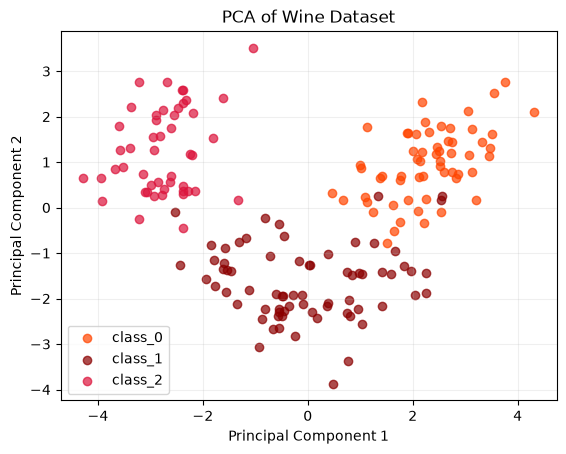

In [5]:
wine_colors = ['orangered', 'darkred', 'crimson']

plt.Figure(figsize=(8, 6))

for class_num, color, target_name in zip(
    [0, 1, 2], wine_colors, target_names
):
    plt.scatter(
        X_reduced[y == class_num, 0],
        X_reduced[y == class_num, 1],
        color=color,
        alpha=0.7,
        label=target_name
    )
plt.title("PCA of Wine Dataset")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.legend()
plt.grid(alpha=0.2)
plt.show()

In [6]:
print("Principal component loadings:")
print(pca.components_)

print("Shape of principal component loadings:", pca.components_.shape)

Principal component loadings:
[[ 0.1443294  -0.24518758 -0.00205106 -0.23932041  0.14199204  0.39466085
   0.4229343  -0.2985331   0.31342949 -0.0886167   0.29671456  0.37616741
   0.28675223]
 [ 0.48365155  0.22493093  0.31606881 -0.0105905   0.299634    0.06503951
  -0.00335981  0.02877949  0.03930172  0.52999567 -0.27923515 -0.16449619
   0.36490283]]
Shape of principal component loadings: (2, 13)


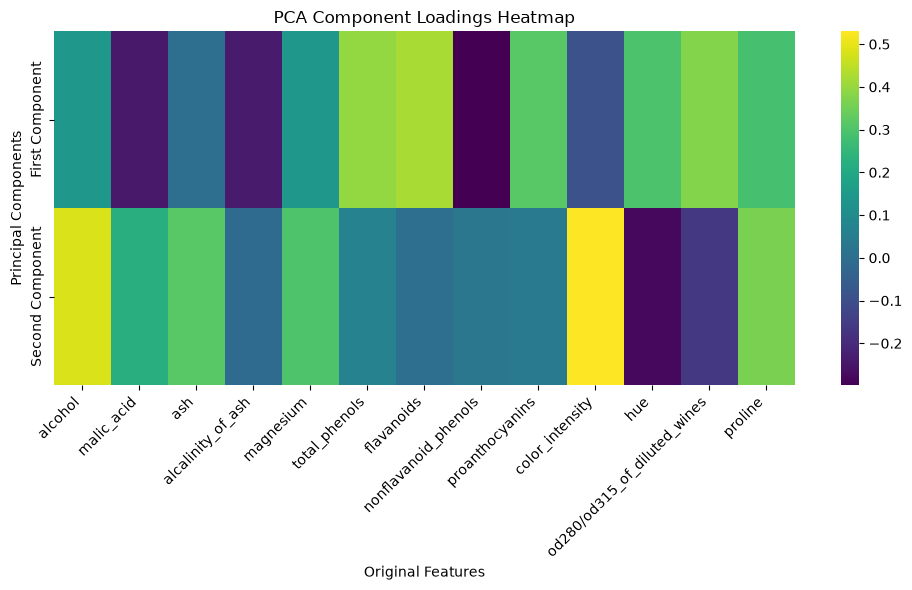

In [8]:
plt.figure(figsize=(10, 6))

sns.heatmap(
    pca.components_,
    cmap = "viridis",
    xticklabels=feat_names,
    yticklabels=["First Component", "Second Component"],
)

plt.title("PCA Component Loadings Heatmap")
plt.xlabel("Original Features")
plt.ylabel("Principal Components")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

In [9]:
print("Explained variance:")
print(pca.explained_variance_)

print("\nExplained variance ratio:")
print(pca.explained_variance_ratio_)

Explained variance:
[4.73243698 2.51108093]

Explained variance ratio:
[0.36198848 0.1920749 ]


In [10]:
pca_3 = PCA(n_components=0.96)
X_reduced_96 = pca_3.fit_transform(X_scaled)

print("Number of components selected:", pca_3.n_components_)
print("Total explained variance:", np.sum(pca_3.explained_variance_ratio_))
print("Reduced dataset shape:", X_reduced_96.shape)

Number of components selected: 10
Total explained variance: 0.9616971684450643
Reduced dataset shape: (178, 10)


**Random Forest Regression**

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error, r2_score


In [12]:
url = (
    "https://archive.ics.uci.edu/ml/"
    "machine-learning-databases/cpu-performance/machine.data"
)

columns = [
    "vendor", "model", "MYCT", "MMIN", "MMAX",
    "CACH", "CHMIN", "CHMAX", "PRP", "ERP"
]

data = pd.read_csv(url, names=columns)

print("First five rows:")
print(data.head())

print("\nDataset shape:", data.shape)
print("\nMissing values:")
print(data.isnull().sum())

First five rows:
    vendor    model  MYCT  MMIN   MMAX  CACH  CHMIN  CHMAX  PRP  ERP
0  adviser    32/60   125   256   6000   256     16    128  198  199
1   amdahl   470v/7    29  8000  32000    32      8     32  269  253
2   amdahl  470v/7a    29  8000  32000    32      8     32  220  253
3   amdahl  470v/7b    29  8000  32000    32      8     32  172  253
4   amdahl  470v/7c    29  8000  16000    32      8     16  132  132

Dataset shape: (209, 10)

Missing values:
vendor    0
model     0
MYCT      0
MMIN      0
MMAX      0
CACH      0
CHMIN     0
CHMAX     0
PRP       0
ERP       0
dtype: int64


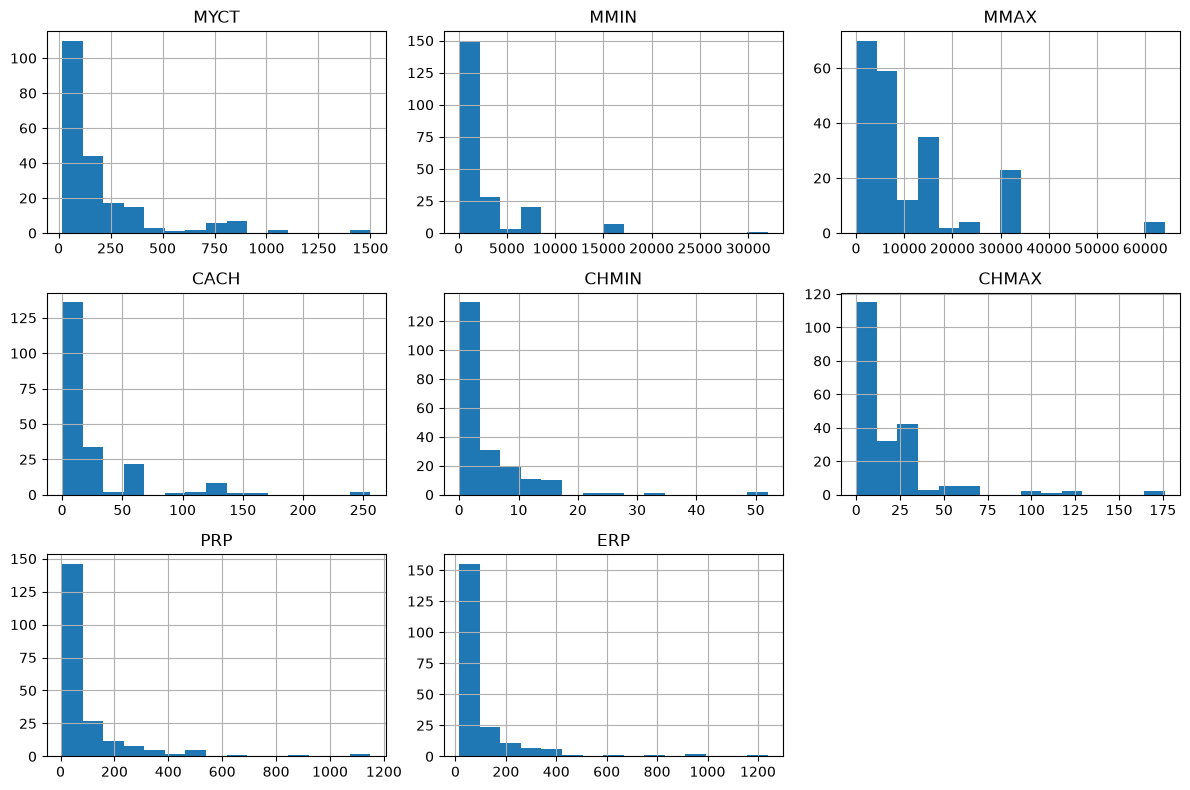

In [13]:
data.hist(figsize=(12, 8), bins=15)
plt.tight_layout()
plt.show()

In [14]:
correlation = data.select_dtypes(include=[np.number]).corr()

print("\nCorrelation with PRP:")
print(correlation["PRP"].sort_values(ascending=False))


Correlation with PRP:
PRP      1.000000
ERP      0.966472
MMAX     0.863004
MMIN     0.794931
CACH     0.662641
CHMIN    0.608903
CHMAX    0.605209
MYCT    -0.307099
Name: PRP, dtype: float64


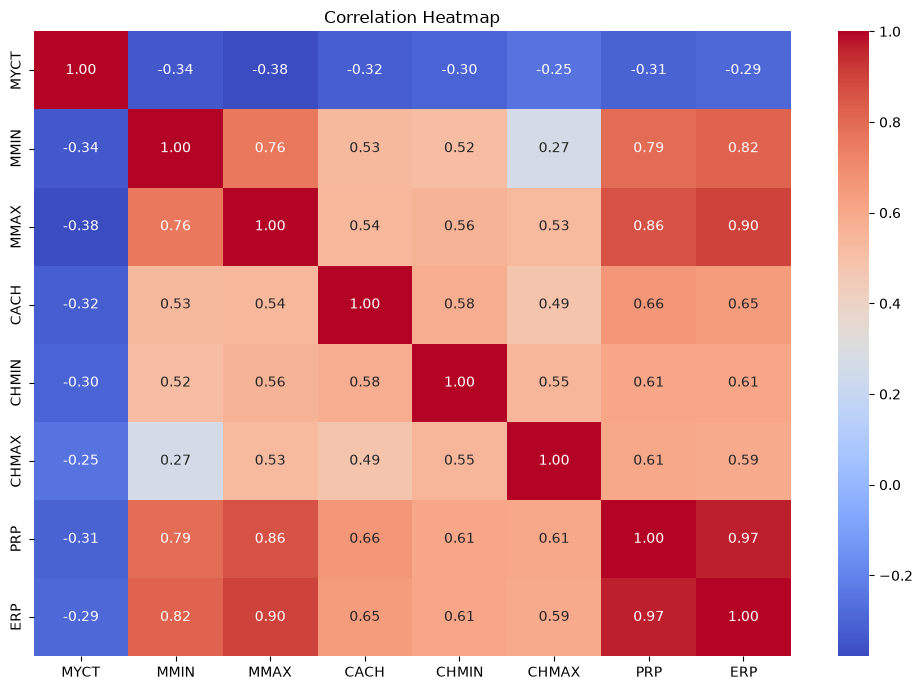

In [15]:
plt.figure(figsize=(10, 7))
sns.heatmap(correlation, annot=True, fmt=".2f", cmap="coolwarm")
plt.title("Correlation Heatmap")
plt.tight_layout()
plt.show()

In [16]:
# Predict PRP using hardware characteristics
X = data.drop(columns=["PRP", "ERP", "vendor", "model"])
y = data["PRP"]

print("\nFeatures:")
print(X.head())

print("\nTarget:")
print(y.head())



Features:
   MYCT  MMIN   MMAX  CACH  CHMIN  CHMAX
0   125   256   6000   256     16    128
1    29  8000  32000    32      8     32
2    29  8000  32000    32      8     32
3    29  8000  32000    32      8     32
4    29  8000  16000    32      8     16

Target:
0    198
1    269
2    220
3    172
4    132
Name: PRP, dtype: int64


In [17]:
X_train, X_test, y_train, y_test = train_test_split( X, y, test_size=0.2, random_state=42 )

print("\nTraining samples:", len(X_train))
print("Testing samples:", len(X_test))

forest_reg = RandomForestRegressor( n_estimators=200, random_state=42, n_jobs=-1 )

forest_reg.fit(X_train, y_train)

y_train_pred = forest_reg.predict(X_train)

train_rmse = np.sqrt( mean_squared_error(y_train, y_train_pred))

train_r2 = r2_score(y_train, y_train_pred)

print("\nInitial Training Results")
print("Training RMSE:", round(train_rmse, 2))
print("Training R2 Score:", round(train_r2, 4))



Training samples: 167
Testing samples: 42

Initial Training Results
Training RMSE: 28.94
Training R2 Score: 0.9564
